# TRUSTSR Lab 03.07 — Final Integrated Reliability Benchmark

**Phase:** Lab 03 — Reliability and evidence integrity  
**Role:** Final capstone lab for Lab 03  
**Status:** Synthetic simulation | Version 1.0.0

## Objective
Integrate the main Lab 03 reliability themes into one compact, reproducible experiment:
- transient delivery failures,
- correlated outage windows,
- ambiguous timeout-after-store,
- idempotent versus non-idempotent receiver storage,
- missing-event and duplicate-storage measurement,
- reconciliation between intended events and receiver records.

## Comparison design
Two receiver policies receive the same synthetic workload:
1. **Idempotent receiver:** unique `event_id`; same ID and same payload is deduplicated.
2. **Non-idempotent receiver:** every successful storage attempt creates another row; retries after an ambiguous timeout can create duplicate rows.

Each condition has 500 intended logical events. Three fixed outage windows affect event indices 0–19, 100–119, and 300–319 (60 events total). All attempts for those events fail before storage. For non-outage events, each attempt can experience an injected pre-storage transient failure or an injected post-store acknowledgement timeout.

**Evidence boundary:** all results are generated by a local synthetic simulation. No real network, remote service, autonomous agent, or production deployment is tested.

> **Revision note (v0.1.1 package review).** The two receiver policies previously used different seeds (the comment claimed they were paired), so `idempotent <= non_idempotent` failed from RNG noise even at retry_limit=1. They now share a seed with per-event common random numbers, making the comparison genuinely paired. Numeric results differ from any earlier run.

## 1. Configuration and environment

In [1]:
import os, json, sqlite3, tempfile, hashlib, random, sys, platform
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261011
N_EVENTS = 500
OUTAGE_STARTS = [0, 100, 300]
OUTAGE_LENGTH = 20
PRE_STORE_FAILURE_PROB = 0.10
POST_STORE_TIMEOUT_PROBS = [0.0, 0.1, 0.3]
RETRY_LIMITS = [1, 3, 5]

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("SQLite:", sqlite3.sqlite_version)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic simulation")
print({"seed": SEED, "events_per_condition": N_EVENTS,
       "outage_starts": OUTAGE_STARTS, "outage_length": OUTAGE_LENGTH,
       "pre_store_failure_probability": PRE_STORE_FAILURE_PROB,
       "post_store_timeout_probabilities": POST_STORE_TIMEOUT_PROBS,
       "retry_limits": RETRY_LIMITS})

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
SQLite: 3.45.1
Execution UTC: 2026-10-11T10:26:37.056983+00:00
Evidence classification: synthetic simulation
{'seed': 20261011, 'events_per_condition': 500, 'outage_starts': [0, 100, 300], 'outage_length': 20, 'pre_store_failure_probability': 0.1, 'post_store_timeout_probabilities': [0.0, 0.1, 0.3], 'retry_limits': [1, 3, 5]}


## 2. Simulation engine

In [2]:
def run_condition(policy, retry_limit, post_timeout_p, seed):
    # rows represent physical stored records. An idempotent receiver stores at most one row per logical event.
    stored_records = []
    intended = []
    event_results = []
    duplicate_store_attempts = 0
    total_attempts = 0
    post_store_timeouts = 0
    outage_set = set()
    for start in OUTAGE_STARTS:
        outage_set.update(range(start, min(start + OUTAGE_LENGTH, N_EVENTS)))

    for i in range(N_EVENTS):
        # Common random numbers: each event has its own stream, and every attempt draws both numbers
        # regardless of policy, so the two receiver policies see identical exogenous randomness.
        rng = random.Random(f"{seed}:{i}")
        event_id = f"event-{i:05d}"
        payload = {"sequence": i, "kind": "synthetic_trustsr_event"}
        payload_hash = hashlib.sha256(json.dumps(payload, sort_keys=True, separators=(",", ":")).encode()).hexdigest()
        intended.append(event_id)
        stored_any = False
        sender_ack = False
        attempts = 0

        for attempt in range(1, retry_limit + 1):
            attempts += 1
            total_attempts += 1
            u_pre, u_post = rng.random(), rng.random()

            # The event is assigned to a persistent outage window; all attempts fail before storage.
            if i in outage_set:
                continue

            # Independent transient failure before receiver storage.
            if u_pre < PRE_STORE_FAILURE_PROB:
                continue

            if policy == "idempotent":
                existing = next((r for r in stored_records if r["event_id"] == event_id), None)
                if existing is not None:
                    if existing["payload_hash"] != payload_hash:
                        raise AssertionError("Same event_id used with conflicting payload.")
                    duplicate_store_attempts += 1
                    stored_any = True
                    sender_ack = True
                    break
                stored_records.append({"event_id": event_id, "payload_hash": payload_hash, "receipt_id": len(stored_records)+1})
            elif policy == "non_idempotent":
                if any(r["event_id"] == event_id for r in stored_records):
                    duplicate_store_attempts += 1
                stored_records.append({"event_id": event_id, "payload_hash": payload_hash, "receipt_id": len(stored_records)+1})
            else:
                raise ValueError("Unknown policy: " + str(policy))

            stored_any = True
            if u_post < post_timeout_p:
                # Storage succeeded, but acknowledgement is lost. Sender retries.
                post_store_timeouts += 1
                continue
            sender_ack = True
            break

        event_results.append({
            "event_id": event_id, "policy": policy, "retry_limit": retry_limit,
            "post_store_timeout_probability": post_timeout_p, "attempts": attempts,
            "in_outage_window": i in outage_set, "receiver_stored": stored_any,
            "sender_observed_ack": sender_ack
        })

    result_df = pd.DataFrame(event_results)
    intended_count = len(intended)
    unique_stored_ids = {r["event_id"] for r in stored_records}
    physical_record_count = len(stored_records)
    duplicate_records = physical_record_count - len(unique_stored_ids)
    missing_ids = set(intended) - unique_stored_ids
    summary = {
        "policy": policy, "retry_limit": retry_limit,
        "post_store_timeout_probability": post_timeout_p,
        "intended_events": intended_count,
        "unique_event_ids_stored": len(unique_stored_ids),
        "physical_receiver_records": physical_record_count,
        "duplicate_records": duplicate_records,
        "duplicate_store_attempts": duplicate_store_attempts,
        "missing_events": len(missing_ids),
        "missing_event_rate": len(missing_ids) / intended_count,
        "unique_event_coverage_rate": len(unique_stored_ids) / intended_count,
        "events_stored_but_sender_ack_missing": int((result_df["receiver_stored"] & ~result_df["sender_observed_ack"]).sum()),
        "mean_attempts_per_event": total_attempts / intended_count,
        "post_store_timeouts_injected": post_store_timeouts,
        "outage_events": int(result_df["in_outage_window"].sum())
    }
    return summary, event_results, stored_records

print("Simulation engine defined.")

Simulation engine defined.


## 3. Run the integrated experiment

In [3]:
summary_rows, event_rows, storage_rows = [], [], []
condition_number = 0
pair_number = 0
for timeout_p in POST_STORE_TIMEOUT_PROBS:
    for retry_limit in RETRY_LIMITS:
        pair_number += 1
        for policy in ["idempotent", "non_idempotent"]:
            condition_number += 1
            # Both policies in a (timeout, retry) pair share one seed and per-event streams (see run_condition).
            seed = SEED + pair_number
            summary, events, storage = run_condition(policy, retry_limit, timeout_p, seed)
            summary_rows.append(summary)
            event_rows.extend(events)
            for record in storage:
                storage_rows.append({"condition_id": condition_number, "policy": policy,
                                     "retry_limit": retry_limit, "post_store_timeout_probability": timeout_p,
                                     **record})

summary_df = pd.DataFrame(summary_rows)
event_df = pd.DataFrame(event_rows)
storage_df = pd.DataFrame(storage_rows)
display(summary_df)
print("Conditions:", len(summary_df))
print("Event-level rows:", len(event_df))
print("Physical receiver records:", len(storage_df))
assert len(summary_df) == len(POST_STORE_TIMEOUT_PROBS) * len(RETRY_LIMITS) * 2
assert len(event_df) == N_EVENTS * len(summary_df)
assert summary_df["unique_event_coverage_rate"].between(0, 1).all()
assert summary_df["missing_event_rate"].between(0, 1).all()
assert (summary_df["unique_event_ids_stored"] + summary_df["missing_events"] == N_EVENTS).all()
print("Integrated experiment structure assertions passed.")

            policy  retry_limit  post_store_timeout_probability  intended_events  unique_event_ids_stored  physical_receiver_records  duplicate_records  duplicate_store_attempts  missing_events  \
0       idempotent            1                             0.0              500                      387                        387                  0                         0             113   
1   non_idempotent            1                             0.0              500                      387                        387                  0                         0             113   
2       idempotent            3                             0.0              500                      440                        440                  0                         0              60   
3   non_idempotent            3                             0.0              500                      440                        440                  0                         0              60   
4       idempot

Conditions: 18
Event-level rows: 9000
Physical receiver records: 8065
Integrated experiment structure assertions passed.


## 4. Compare receiver policies

In [4]:
comparison_cols = [
    "policy", "retry_limit", "post_store_timeout_probability",
    "unique_event_coverage_rate", "missing_event_rate",
    "physical_receiver_records", "duplicate_records",
    "events_stored_but_sender_ack_missing", "mean_attempts_per_event"
]
comparison_df = summary_df[comparison_cols].sort_values(
    ["post_store_timeout_probability", "retry_limit", "policy"]
).reset_index(drop=True)
display(comparison_df)

# Within every retry/timeout condition, the idempotent receiver must not have more physical rows than the non-idempotent receiver.
wide_records = summary_df.pivot(index=["retry_limit", "post_store_timeout_probability"],
                                columns="policy", values="physical_receiver_records")
assert (wide_records["idempotent"] <= wide_records["non_idempotent"]).all()

wide_duplicates = summary_df.pivot(index=["retry_limit", "post_store_timeout_probability"],
                                   columns="policy", values="duplicate_records")
assert (wide_duplicates["idempotent"] == 0).all()
assert (wide_duplicates["non_idempotent"] >= 0).all()
print("Policy comparison assertions passed.")

            policy  retry_limit  post_store_timeout_probability  unique_event_coverage_rate  missing_event_rate  physical_receiver_records  duplicate_records  events_stored_but_sender_ack_missing  \
0       idempotent            1                             0.0                       0.774               0.226                        387                  0                                     0   
1   non_idempotent            1                             0.0                       0.774               0.226                        387                  0                                     0   
2       idempotent            3                             0.0                       0.880               0.120                        440                  0                                     0   
3   non_idempotent            3                             0.0                       0.880               0.120                        440                  0                                     0   
4    

Policy comparison assertions passed.


## 5. Reconciliation and invariants

In [5]:
reconciliation_rows = []
for (policy, retry_limit, timeout_p), group in event_df.groupby(
        ["policy", "retry_limit", "post_store_timeout_probability"]):
    intended_ids = set(group["event_id"])
    records = storage_df[
        (storage_df["policy"] == policy) &
        (storage_df["retry_limit"] == retry_limit) &
        (storage_df["post_store_timeout_probability"] == timeout_p)
    ]
    stored_ids = set(records["event_id"])
    reconciliation_rows.append({
        "policy": policy, "retry_limit": retry_limit,
        "post_store_timeout_probability": timeout_p,
        "intended_unique_ids": len(intended_ids),
        "stored_unique_ids": len(stored_ids),
        "missing_unique_ids": len(intended_ids - stored_ids),
        "extra_or_duplicate_physical_rows": len(records) - len(stored_ids),
        "reconciled": intended_ids == (stored_ids | (intended_ids - stored_ids))
    })

reconciliation_df = pd.DataFrame(reconciliation_rows)
display(reconciliation_df)
assert (reconciliation_df["intended_unique_ids"] == N_EVENTS).all()
assert (reconciliation_df["stored_unique_ids"] + reconciliation_df["missing_unique_ids"] == N_EVENTS).all()
assert (reconciliation_df["extra_or_duplicate_physical_rows"] >= 0).all()

# Every configured outage event remains missing in this persistent-outage model.
outage_event_df = event_df[event_df["in_outage_window"]]
assert len(outage_event_df) == len(summary_df) * 60
assert not outage_event_df["receiver_stored"].any()
assert (summary_df["outage_events"] == 60).all()
print("Reconciliation and outage invariants passed.")

            policy  retry_limit  post_store_timeout_probability  intended_unique_ids  stored_unique_ids  missing_unique_ids  extra_or_duplicate_physical_rows  reconciled
0       idempotent            1                             0.0                  500                387                 113                                 0        True
1       idempotent            1                             0.1                  500                411                  89                                 0        True
2       idempotent            1                             0.3                  500                392                 108                                 0        True
3       idempotent            3                             0.0                  500                440                  60                                 0        True
4       idempotent            3                             0.1                  500                439                  61                           

Reconciliation and outage invariants passed.


## 6. Plots

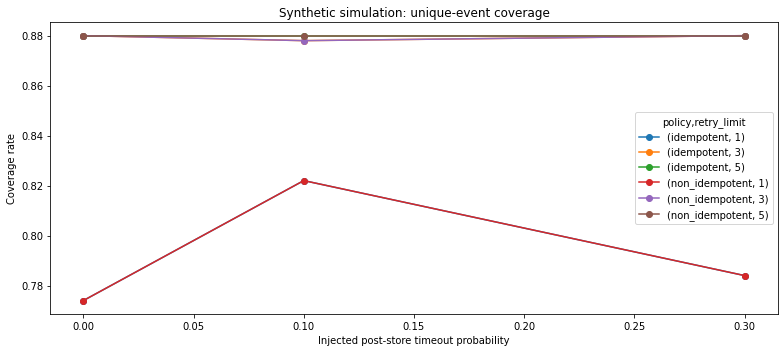

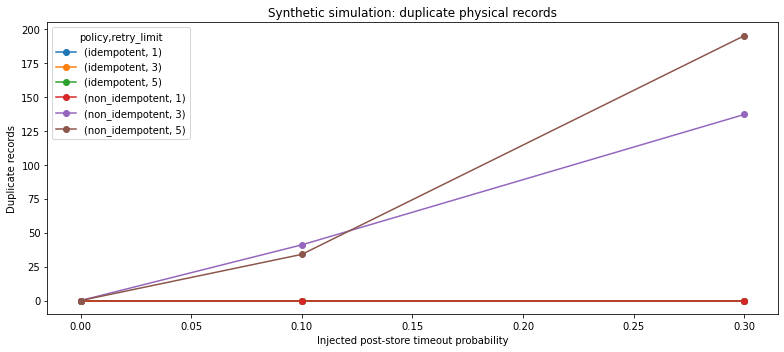

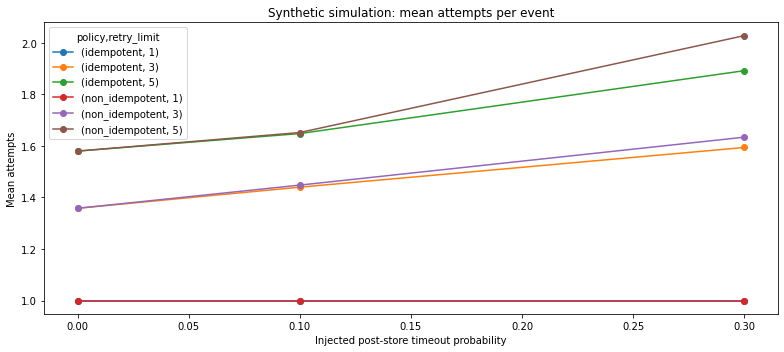

In [6]:
for metric, title, ylabel in [
    ("unique_event_coverage_rate", "Synthetic simulation: unique-event coverage", "Coverage rate"),
    ("duplicate_records", "Synthetic simulation: duplicate physical records", "Duplicate records"),
    ("mean_attempts_per_event", "Synthetic simulation: mean attempts per event", "Mean attempts")
]:
    pivot = summary_df.pivot_table(index="post_store_timeout_probability",
                                   columns=["policy", "retry_limit"], values=metric)
    ax = pivot.plot(marker="o", figsize=(11, 5))
    ax.set_title(title)
    ax.set_xlabel("Injected post-store timeout probability")
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()

## 7. Export reproducibility artifacts

In [7]:
summary_df.to_csv("trustsr_lab03_07_final_summary.csv", index=False)
comparison_df.to_csv("trustsr_lab03_07_policy_comparison.csv", index=False)
event_df.to_csv("trustsr_lab03_07_event_level.csv", index=False)
storage_df.to_csv("trustsr_lab03_07_receiver_records.csv", index=False)
reconciliation_df.to_csv("trustsr_lab03_07_reconciliation.csv", index=False)
print("CSV exports created:")
for filename in [
    "trustsr_lab03_07_final_summary.csv",
    "trustsr_lab03_07_policy_comparison.csv",
    "trustsr_lab03_07_event_level.csv",
    "trustsr_lab03_07_receiver_records.csv",
    "trustsr_lab03_07_reconciliation.csv"
]:
    print("-", filename)
print("Evidence classification: synthetic simulation only.")

CSV exports created:
- trustsr_lab03_07_final_summary.csv
- trustsr_lab03_07_policy_comparison.csv
- trustsr_lab03_07_event_level.csv
- trustsr_lab03_07_receiver_records.csv
- trustsr_lab03_07_reconciliation.csv
Evidence classification: synthetic simulation only.


## 8. Final assertions and defensible conclusions

```text
All TRUSTSR Lab 03.07 assertions passed.
```

### Claims this experiment can support
- In this synthetic model, the idempotent receiver stores at most one physical row per event ID.
- The non-idempotent receiver can store duplicate physical rows after ambiguous post-store timeouts.
- The configured persistent outage windows leave 60 of 500 events missing per condition, independent of retry limit.
- The effect of retry limits and post-store timeout probabilities can be compared under the exact assumptions above.

### Claims this experiment cannot support
- Production reliability, real-world failure rates, network performance, or exactly-once delivery across distributed services.
- Superiority of the overall TRUSTSR architecture.
- Crash safety, remote journal durability, or security against a privileged database attacker.
- Generalization beyond the chosen seed, workload, and failure model.

### Final reporting rule
Report the seed, event count, outage schedule, probabilities, retry limits, exact metrics, and CSV files. Separate **synthetic model output** from **measured production evidence**. Do not use the simulated percentages as empirical claims about real systems.